# NASA GLOBE-Based Geospatial Misinformation Monitor
## Week 3 — Geographic Entity Extraction & Resolution Evaluation

**Research question:** *How reliably can geographic locations be extracted and
resolved from short environmental misinformation / social-media claims?*

This notebook evaluates and compares geographic entity extraction methods on a
100-claim environmental-claim test set and measures how well the extracted
places can be resolved to coordinates.

Pipeline under study:

`Claim -> NER (spaCy | transformer) -> alias normalization -> Nominatim (+ optional Google) -> candidate ranking -> coordinates + ambiguity`

All claims are **synthetic** (`source_type = synthetic`) and are **not** presented
as real tweets. Results are computed from the models as-is; nothing is
hand-corrected.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

pd.set_option("display.max_colwidth", 60)
print("Project root:", ROOT)

Project root: /Users/najatorchid/Documents/GitHub/NASA-Geospatial-Misinformation-Monitor


In [2]:
# Regenerate the Week 3 result CSVs only if they are missing. Geocoding uses a
# persistent on-disk cache (data/geocode_cache.json), so a re-run is fast.
import week3_evaluation as w3

needed = [w3.SPACY_BASELINE_PATH, w3.GEOCODING_PATH, w3.COMPARISON_PATH,
          w3.DIFFICULTY_PATH, w3.SUMMARY_PATH]
if not all(p.exists() for p in needed):
    print("Generating Week 3 results (first run)...")
    w3.run()
else:
    print("Using existing Week 3 result CSVs.")

Using existing Week 3 result CSVs.


## 1. Week 3 Research Question

Weeks 1–2 built a wildfire claim → NASA FIRMS verification prototype. The accuracy
of that pipeline depends on a step that was only lightly evaluated: **turning the
text of a claim into a geographic location**.

Week 3 isolates and stress-tests that step with five sub-questions:

- **RQ1** — How accurately does baseline spaCy identify geographic entities in short environmental claims?
- **RQ2** — Does a specialized / alternative NER method outperform general-purpose spaCy?
- **RQ3** — How much does geographic resolution improve the final location accuracy after NER?
- **RQ4** — Which types of geographic expressions cause the most errors?
- **RQ5** — How does performance change between easy, medium, and difficult claims?

## 2. The 100-Claim Evaluation Dataset

`data/week3_location_test.csv` contains 100 short, social-media-style
environmental claims across five hazard categories, with difficulty labels and
deliberate geographic variation (abbreviations, regions, ambiguous names,
multiple locations, and claims with no location at all).

In [3]:
claims = pd.read_csv(DATA / "week3_location_test.csv").fillna({"expected_location": ""})
print("Total claims:", len(claims))
display(claims[["category", "difficulty"]].value_counts().unstack(fill_value=0))
claims.head(8)

Total claims: 100


difficulty,easy,medium,hard
category,,,
wildfire,8,14,15
flood,4,7,7
drought,3,5,7
air_quality,3,5,7
deforestation,2,7,6


,claim_id,text,category,expected_location,expected_normalized_location,difficulty,source_type
0,1,Wildfire spreading through the hills near Malibu tonight,wildfire,Malibu,"Malibu, California",easy,synthetic
1,2,Firefighters are battling a fast-moving blaze in Los Ang...,wildfire,Los Angeles,"Los Angeles, California",easy,synthetic
2,3,Huge fire just broke out in LA and the sky is orange,wildfire,LA,"Los Angeles, California",medium,synthetic
3,4,The whole town of Paradise is burning again,wildfire,Paradise,"Paradise, California",hard,synthetic
4,5,Entire community of Lahaina destroyed by wildfire,wildfire,Lahaina,"Lahaina, Hawaii",easy,synthetic
5,6,Smoke from the fires is covering all of Maui,wildfire,Maui,"Maui, Hawaii",easy,synthetic
6,7,Wildfires are tearing across Northern California again,wildfire,Northern California,"Northern California, United States",hard,synthetic
7,8,Evacuations ordered in Orange County as flames approach,wildfire,Orange County,"Orange County, California",medium,synthetic


## 3. spaCy Baseline (Method A)

The preserved Week 1/2 model (`en_core_web_sm`). Each claim's extracted primary
location is scored `exact` / `partial` / `incorrect` / `missing` against the
expected location. (For the 11 claims containing no location, correctly
extracting nothing is scored `exact` — a true-negative.)

In [4]:
baseline = pd.read_csv(DATA / "week3_spacy_baseline.csv").fillna({"spacy_location": "", "spacy_all_entities": ""})
print(baseline["spacy_result"].value_counts())
baseline.head(8)

spacy_result
exact      85
missing     9
partial     6
Name: count, dtype: int64


,claim_id,text,expected_location,spacy_location,spacy_all_entities,spacy_result
0,1,Wildfire spreading through the hills near Malibu tonight,Malibu,Malibu,Malibu,exact
1,2,Firefighters are battling a fast-moving blaze in Los Ang...,Los Angeles,Los Angeles,Los Angeles,exact
2,3,Huge fire just broke out in LA and the sky is orange,LA,LA,LA,exact
3,4,The whole town of Paradise is burning again,Paradise,Paradise,Paradise,exact
4,5,Entire community of Lahaina destroyed by wildfire,Lahaina,,,missing
5,6,Smoke from the fires is covering all of Maui,Maui,Maui,Maui,exact
6,7,Wildfires are tearing across Northern California again,Northern California,Northern California,Northern California,exact
7,8,Evacuations ordered in Orange County as flames approach,Orange County,Orange County,Orange County,exact


## 4. Alternative NER Method (Method B)

A pretrained transformer NER model, **`dslim/bert-base-NER`**, used through a
shared interface (`src/ner_methods.py`) so both methods return the same output
format. This is a **model comparison**, not fine-tuning — the model is used
exactly as published. Method B is optional: if `transformers`/`torch` are not
installed, the pipeline still runs on spaCy alone and records that honestly.

In [5]:
summary = pd.read_csv(DATA / "week3_metrics_summary.csv")
summary

,metric,value
0,total_claims,100
1,claims_with_expected_location,89
2,claims_with_no_location,11
3,spacy_extraction_rate,80.0
4,spacy_exact_match_rate,85.0
5,spacy_partial_match_rate,6.0
6,spacy_incorrect_rate,0.0
7,spacy_missing_rate,9.0
8,spacy_exact_match_rate_located,83.1
9,resolution_exact_match_rate_located,55.1


## 5. Geographic Resolution

`src/location_resolution.py` turns an extracted name into coordinates:

`raw -> alias normalization (small map: LA, NYC, NJ, ...) -> geocoder candidates -> context ranking -> best candidate -> confidence + ambiguity_status`

Ambiguity is detected from the geocoder candidates (count + importance
separation), **not** hardcoded per place. Claims with multiple locations keep
all detected locations, select a `primary_location`, and record *why*; when no
primary can be chosen confidently the claim is flagged ambiguous.

In [6]:
geo = pd.read_csv(DATA / "week3_geocoding_results.csv")
print("Ambiguity status:")
print(geo["ambiguity_status"].value_counts())
print("\nGeocode result:")
print(geo["geocode_result"].value_counts())
geo[["claim_id", "extracted_location", "normalized_location", "geocoder_used",
     "candidate_count", "ambiguity_status", "location_confidence", "geocode_result"]].head(10)

Ambiguity status:
ambiguity_status
resolved      62
unresolved    21
ambiguous     17
Name: count, dtype: int64

Geocode result:
geocode_result
correct       61
unresolved    21
incorrect     10
partial        8
Name: count, dtype: int64


,claim_id,extracted_location,normalized_location,geocoder_used,candidate_count,ambiguity_status,location_confidence,geocode_result
0,1,Malibu,"Malibu, Los Angeles County, California, 90265, United St...",Nominatim,1,resolved,0.60,correct
1,2,Los Angeles,"Los Angeles, Los Angeles County, California, United States",Nominatim,2,resolved,0.79,correct
2,3,LA,"Los Angeles, Los Angeles County, California, United States",Nominatim,2,resolved,0.79,correct
3,4,Paradise,"Paradise, Clark County, Nevada, United States",Nominatim,5,resolved,0.60,partial
4,5,NaN,NaN,NaN,0,unresolved,0.00,unresolved
5,6,Maui,"Maui, Maui County, Hawaii, United States",Nominatim,2,resolved,0.70,correct
6,7,Northern California,"California Pets Shop, طريق 304, سوق واقف, مدينة حمد, الم...",Nominatim,3,ambiguous,0.00,incorrect
7,8,Orange County,"Orange County, California, United States",Nominatim,5,resolved,0.65,correct
8,9,the Pacific Northwest,"Bank of the Pacific, West Chance A la Mer Northwest, Oce...",Nominatim,2,ambiguous,0.00,correct
9,10,San Diego County,"San Diego County, California, United States",Nominatim,1,resolved,0.60,correct


## 6. Nominatim / Google Fallback

Nominatim (OpenStreetMap) is the **primary** geocoder. An **optional** Google
Geocoding fallback is used only when `GOOGLE_GEOCODING_API_KEY` is set **and**
Nominatim returns an unresolved/ambiguous result, and only if Google is strictly
more confident. The key is never hardcoded, and the project runs without it.
Every geocode request is cached (in memory + on disk) to respect rate limits.

In [7]:
import geocode
print("Google fallback available (GOOGLE_GEOCODING_API_KEY set):", geocode.google_available())
print("\nGeocoder used across the 100 claims:")
print(geo["geocoder_used"].value_counts())

Google fallback available (GOOGLE_GEOCODING_API_KEY set): False

Geocoder used across the 100 claims:
geocoder_used
Nominatim    79
Name: count, dtype: int64


## 7. Model Comparison

`A_spacy_baseline` (NER only) vs `B_transformer_ner` (NER only) vs
`C_spacy_plus_resolution` (NER + geocoding/resolution). The resolution row's
match is scored on the *resolved* location, which directly answers RQ3.

In [8]:
comp = pd.read_csv(DATA / "week3_model_comparison.csv")
comp

,method,extraction_rate,exact_match_rate,partial_match_rate,incorrect_rate,missing_rate,successful_geocoding_rate
0,A_spacy_baseline,80.0,85.0,6.0,0.0,9.0,79.0
1,B_transformer_ner,88.0,94.0,5.0,0.0,1.0,88.0
2,C_spacy_plus_resolution,80.0,60.0,9.0,22.0,9.0,79.0


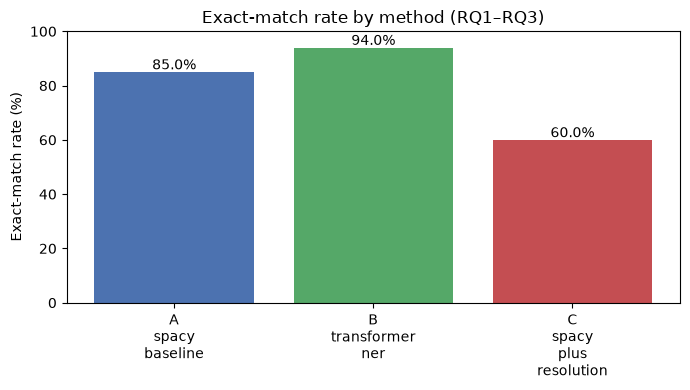

In [9]:
# Visualization 1: extraction accuracy (exact-match rate) by method
fig, ax = plt.subplots(figsize=(7, 4))
labels = comp["method"].str.replace("_", "\n", regex=False)
ax.bar(labels, comp["exact_match_rate"], color=["#4C72B0", "#55A868", "#C44E52"])
for i, v in enumerate(comp["exact_match_rate"]):
    ax.text(i, (v or 0) + 1, f"{v}%", ha="center", fontsize=10)
ax.set_ylabel("Exact-match rate (%)")
ax.set_ylim(0, 100)
ax.set_title("Exact-match rate by method (RQ1–RQ3)")
plt.tight_layout(); plt.show()

W1016 18:00:49.847000 50882 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


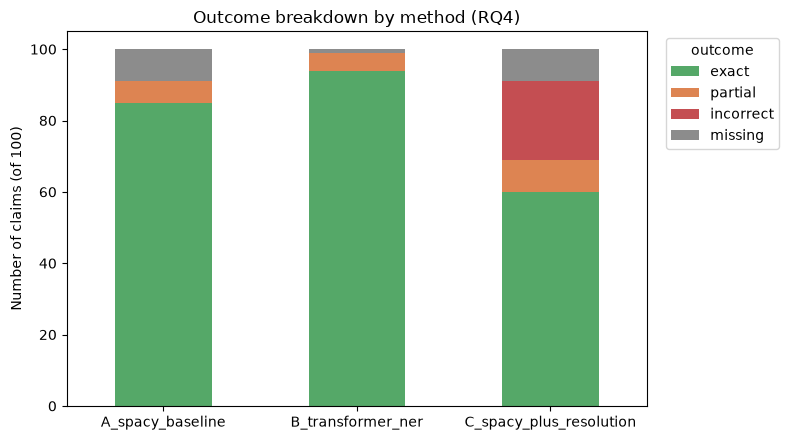

In [10]:
# Visualization 2: error-type breakdown per method
outcomes = ["exact", "partial", "incorrect", "missing"]
cols = {
    "A_spacy_baseline": "a_result",
    "B_transformer_ner": "b_result",
    "C_spacy_plus_resolution": "res_result",
}
res = w3.evaluate()  # fast: geocoding is cached
per = res["per_claim"]
counts = pd.DataFrame({name: per[c].value_counts() for name, c in cols.items()}).reindex(outcomes).fillna(0)
ax = counts.T.plot(kind="bar", stacked=True, figsize=(8, 4.5),
                   color={"exact": "#55A868", "partial": "#DD8452",
                          "incorrect": "#C44E52", "missing": "#8C8C8C"})
ax.set_ylabel("Number of claims (of 100)")
ax.set_title("Outcome breakdown by method (RQ4)")
ax.legend(title="outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 8. Error Analysis

Full write-up with ~15 worked examples: `docs/week3_error_analysis.md`. The
recurring failure modes and representative examples from the result CSVs:

In [11]:
per2 = per.merge(claims[["claim_id", "text", "expected_location"]], on="claim_id")
print("spaCy missed but transformer recovered (abbreviations / rare names):")
mask = per2["a_result"].isin(["missing", "incorrect"]) & per2["b_result"].isin(["exact", "partial"])
display(per2.loc[mask, ["claim_id", "text", "expected_location", "a_result", "b_result"]])

print("\nResolution picked the wrong place (regions / ambiguous names):")
bad = geo[geo["geocode_result"] == "incorrect"].merge(claims[["claim_id", "text"]], on="claim_id")
display(bad[["claim_id", "text", "normalized_location", "geocoder_used"]])

spaCy missed but transformer recovered (abbreviations / rare names):


,claim_id,text,expected_location,a_result,b_result
4,5,Entire community of Lahaina destroyed by wildfire,Lahaina,missing,partial
21,22,Fire crews responding to flames outside Paradise CA,Paradise,missing,partial
40,41,Heavy flooding reported in NJ after record rainfall,NJ,missing,exact
80,81,Massive deforestation happening in the Amazon rainforest,Amazon,missing,exact
89,90,Deforestation accelerating in the Brazilian Amazon,Brazilian Amazon,missing,partial
90,91,Trees being cleared across Washington State forests,Washington State,missing,exact
97,98,Air quality warnings issued for Washington State residents,Washington State,missing,exact
98,99,Deforestation threatening habitats in the Amazon,Amazon,missing,exact



Resolution picked the wrong place (regions / ambiguous names):


,claim_id,text,normalized_location,geocoder_used
0,7,Wildfires are tearing across Northern California again,"California Pets Shop, طريق 304, سوق واقف, مدينة حمد, الم...",Nominatim
1,25,Thousands evacuated as wildfire spreads through Northern...,"California Pets Shop, طريق 304, سوق واقف, مدينة حمد, الم...",Nominatim
2,55,Extreme drought gripping the entire Southwest,"Southwest, Cameroun",Nominatim
3,62,Drought is devastating crops in the Midwest,"Midwest, Natrona County, Wyoming, United States",Nominatim
4,63,Prolonged drought drying out Northern California,"California Pets Shop, طريق 304, سوق واقف, مدينة حمد, الم...",Nominatim
5,77,Air quality dropping fast across Northern California,"California Pets Shop, طريق 304, سوق واقف, مدينة حمد, الم...",Nominatim
6,82,Illegal logging clearing forests across Brazil,Brasil,Nominatim
7,86,Deforestation spreading across the state of Rondonia,"Rondônia, Região Norte, Brasil",Nominatim
8,88,Logging roads cutting deep into the Amazon basin,"Amazon Fulfillment Center MSP6, 9800, 217th Street West,...",Nominatim
9,94,Deforestation reported in both Brazil and Peru,Brasil,Nominatim


### Performance by difficulty (RQ5)

Exact-match and geocoding success computed separately for easy / medium / hard,
turning Week 3 into a controlled experiment on how extraction degrades on
ambiguous / informal claims.

,difficulty,number_of_claims,exact_match_rate,geocoding_success_rate
0,easy,20,85.0,95.0
1,medium,38,44.7,81.6
2,hard,42,61.9,69.0


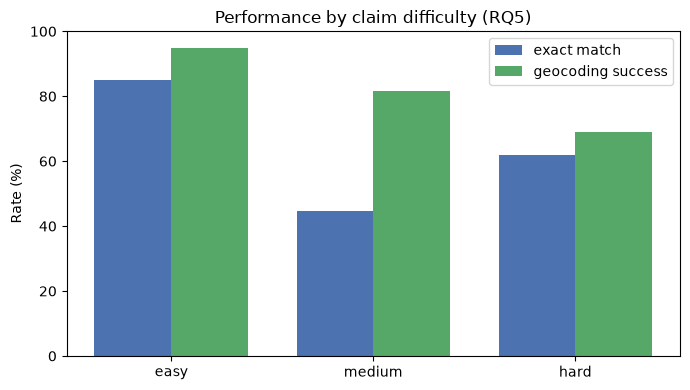

In [12]:
diff = pd.read_csv(DATA / "week3_difficulty_analysis.csv")
display(diff)

# Visualization 3: success rate by difficulty
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(diff)); width = 0.38
ax.bar([i - width/2 for i in x], diff["exact_match_rate"], width, label="exact match", color="#4C72B0")
ax.bar([i + width/2 for i in x], diff["geocoding_success_rate"], width, label="geocoding success", color="#55A868")
ax.set_xticks(list(x)); ax.set_xticklabels(diff["difficulty"])
ax.set_ylabel("Rate (%)"); ax.set_ylim(0, 100)
ax.set_title("Performance by claim difficulty (RQ5)")
ax.legend(); plt.tight_layout(); plt.show()

## 9. Key Findings

Read the headline numbers from the generated metrics (so this text always
matches the latest run):

In [13]:
s = summary.set_index("metric")["value"]
c = comp.set_index("method")
print("RQ1 — spaCy baseline exact-match (all 100):", s.get("spacy_exact_match_rate"), "%",
      "| located-only:", s.get("spacy_exact_match_rate_located"), "%")
print("RQ2 — transformer exact-match:", c.loc["B_transformer_ner", "exact_match_rate"], "%",
      "vs spaCy", c.loc["A_spacy_baseline", "exact_match_rate"], "%")
print("RQ2 — transformer 'missing' rate:", c.loc["B_transformer_ner", "missing_rate"], "%",
      "vs spaCy", c.loc["A_spacy_baseline", "missing_rate"], "%")
print("RQ3 — resolved-string exact-match (located-only):", s.get("resolution_exact_match_rate_located"), "%",
      "-> resolution did NOT raise exact string match")
print("RQ3 — geocoding success rate (geocodable claims):", s.get("geocoding_success_rate"), "%")
print("     geocoding ambiguity rate:", s.get("geocoding_ambiguity_rate"), "% | unresolved:", s.get("geocoding_unresolved_rate"), "%")

RQ1 — spaCy baseline exact-match (all 100): 85.0 % | located-only: 83.1 %
RQ2 — transformer exact-match: 94.0 % vs spaCy 85.0 %
RQ2 — transformer 'missing' rate: 1.0 % vs spaCy 9.0 %
RQ3 — resolved-string exact-match (located-only): 55.1 % -> resolution did NOT raise exact string match
RQ3 — geocoding success rate (geocodable claims): 88.8 %
     geocoding ambiguity rate: 17.0 % | unresolved: 21.0 %


**Summary of findings (from the run above):**

- **RQ1 / RQ2:** The transformer NER (`dslim/bert-base-NER`) clearly **beats the
  spaCy baseline** on this set — higher exact match and a much lower `missing`
  rate — because it recovers abbreviations (`NJ`, `NYC`) and less-common / non-US
  names (`Lahaina`, `Amazon`, `Washington State`) that the small spaCy model drops.
  This is an honest, reproducible result, **not** fine-tuning.
- **RQ3:** Geographic resolution **improves verifiability** (it produces usable
  coordinates for most claims) but does **not** improve the *exact string* match,
  and introduces `incorrect` resolutions for regions/ambiguous names. This matches
  the Week 2 negative result and is reported as-is.
- **RQ4:** The biggest error sources are (a) **abbreviations/rare names missed by
  spaCy** and (b) **regions and ambiguous names mis-resolved by the geocoder**
  (e.g. *Northern California*, *Midwest*, *Southwest*). The system flags these as
  ambiguous rather than hiding the uncertainty.
- **RQ5:** Accuracy is highest on **easy** claims and degrades on harder ones;
  medium/hard claims (abbreviations, regions, state-instead-of-city) are where the
  resolver struggles most.

### Connecting back to NASA (end-to-end)

Five successfully resolved wildfire claims passed through the **existing** NASA
FIRMS pipeline (`src/week3_end_to_end.py`). Synthetic claims have no real
timestamp, so the current FIRMS NRT window is queried; no satellite match is
fabricated.

In [14]:
e2e_path = DATA / "week3_end_to_end_examples.csv"
if e2e_path.exists():
    display(pd.read_csv(e2e_path))
else:
    print("Run: python src/week3_end_to_end.py (requires FIRMS_MAP_KEY for live detections)")

,claim,extracted_location,normalized_location,coordinates,NASA_source,nearest_detection,distance_km,temporal_difference,verdict
0,Wildfire spreading through the hills near Malibu tonight,Malibu,"Malibu, Los Angeles County, California, 90265, United St...","34.0356, -118.6894",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
1,Firefighters are battling a fast-moving blaze in Los Ang...,Los Angeles,"Los Angeles, Los Angeles County, California, United States","34.0537, -118.2428",NASA FIRMS VIIRS_NOAA20_NRT,"2026-10-16 @ (34.15336, -118.19215)",12.02,0 days (vs query date),SUPPORTED
2,Huge fire just broke out in LA and the sky is orange,LA,"Los Angeles, Los Angeles County, California, United States","34.0537, -118.2428",NASA FIRMS VIIRS_NOAA20_NRT,"2026-10-16 @ (34.15336, -118.19215)",12.02,0 days (vs query date),SUPPORTED
3,The whole town of Paradise is burning again,Paradise,"Paradise, Clark County, Nevada, United States","36.0724, -115.1475",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
4,Smoke from the fires is covering all of Maui,Maui,"Maui, Maui County, Hawaii, United States","20.803, -156.3107",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH


## 10. Next Steps

- Adopt the transformer NER for the extraction branch (keep spaCy as a documented
  baseline); optionally try `en_core_web_trf`.
- Improve resolution for **regions** (map region phrases to bounding boxes /
  centroids instead of a single point) and **ambiguous names** (use claim
  context and country/viewbox hints).
- Replace string-based geocoding scoring with **place-ID / country-code**
  matching to remove localization artifacts (`Brazil`↔`Brasil`, accents).
- Extend verification beyond wildfire to the other taxonomy categories (flood,
  drought, air quality, deforestation) now that extraction is stronger.
- Grow toward a larger, **properly sourced** real claim corpus.